# Radical voting: France and the reference episodes

How large is the radical vote, who drives it, and how did it move around the reference shocks?

- **Radical** = parties that **The PopuList 4.0** classes as far right or far left.
- **Votes** = PPEG parliamentary election results (first round in France).
- The link between the two is `data/reference/radical_parties.csv` (see its README).

Two judgment calls are kept visible rather than settled here:
- **Les Républicains**: PopuList 4.0 codes LR (UMP from 2002) as far right. It is shown separately as *disputed*.
- **New Popular Front 2024**: one alliance row containing radical (LFI, PCF) and non-radical (PS, Ecologists) parties. It is shown as a range.

**These are observations, not effects or forecasts.**

In [1]:
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data/raw'
pd.set_option('display.float_format', '{:.1f}'.format)
COUNTRIES = {'FRA': 'France', 'BEL': 'Belgium', 'ESP': 'Spain', 'GRC': 'Greece',
             'PRT': 'Portugal', 'IRL': 'Ireland', 'AUT': 'Austria', 'ITA': 'Italy'}

crosswalk = pd.read_csv(ROOT / 'data/reference/radical_parties.csv')
# Lists that are one political family under several names (e.g. IU -> Unidos Podemos), so renamings are not read as gains or losses.
FAMILY = pd.read_csv(ROOT / 'data/reference/party_lists.csv').set_index('party_id').list_family.to_dict()
FAMILY['FR604'] = 'LFI + PCF'  # NFP 2024, counted below at its estimated radical part only
with ZipFile(RAW / 'ppeg_2025v1/ppeg_parl_2025v1.zip') as archive:
    ppeg = pd.read_csv(archive.open('ppeg_parl_2025v1.csv'), low_memory=False)
ppeg['edate'] = pd.to_datetime(ppeg.edate)
episodes = pd.read_csv(RAW / 'shocks/episodes.csv')
episodes['start_date'] = pd.to_datetime(episodes.start)
episodes['end_date'] = pd.to_datetime(episodes.end) + pd.offsets.MonthEnd(0)
# Readable episode names (country and years). The short IDs (e.g. S1_BE_2010) are only used inside the code.
years = lambda r: r.start[:4] + ('' if r.start[:4] == r.end[:4] else '–' + r.end[2:4])
episodes['episode'] = [f'{r.country} {years(r)}' for r in episodes.itertuples()]
LABEL = dict(zip(episodes.episode_id, episodes.episode))

def named(df):
    # Replace episode IDs by 'Country years' in a table's index or 'episode' column.
    df = df.rename(index=LABEL)
    return df.assign(episode=df.episode.map(LABEL)) if 'episode' in df.columns else df

# One row per party and election, with its radical group.
votes = ppeg[ppeg.iso3c.isin(COUNTRIES)].merge(
    crosswalk[['iso3', 'party_id', 'family', 'first_year', 'last_year', 'note']],
    left_on=['iso3c', 'party_id'], right_on=['iso3', 'party_id'], how='left')
in_years = votes.edate.dt.year.between(votes.first_year, votes.last_year)
note = votes.note.fillna('')
votes['group'] = np.select([votes.family.isna() | ~in_years, note.str.startswith('DISPUTED'), note.str.startswith('PARTIAL')],
                           ['other', 'disputed', 'partial'], default=votes.family)
votes['pct'] = votes.v_share * 100
votes['party'] = votes.pinitials.fillna(votes.pname_en)

# One row per election: far right, far left, and the two judgment calls kept apart.
elections = (votes.pivot_table(index=['iso3c', 'edate'], columns='group', values='pct', aggfunc='sum', fill_value=0)
             .reindex(columns=['far_right', 'far_left', 'disputed', 'partial', 'other'], fill_value=0).reset_index())
elections['radical'] = elections.far_right + elections.far_left

# NFP 2024 (the only PARTIAL row): its radical part is estimated with the LFI + PCF share of NUPES in 2022,
# where PPEG gives party-level estimates for the same alliance partners.
nupes = votes[(votes.iso3c == 'FRA') & (votes.edate == '2022-06-12') & (votes.alliance_initials == 'NUPES')]
NFP_RADICAL_SHARE = nupes.loc[nupes.group == 'far_left', 'v_share'].sum() / nupes.v_share.sum()
elections['far_left_central'] = elections.far_left + NFP_RADICAL_SHARE * elections.partial
elections['radical_central'] = elections.far_right + elections.far_left_central
elections['country'] = elections.iso3c.map(COUNTRIES)
elections.columns.name = None
print(f"{len(elections)} elections in {elections.country.nunique()} countries, "
      f"{elections.edate.dt.year.min()}–{elections.edate.dt.year.max()}")

168 elections in 8 countries, 1944–2025


## 1. The classification

How many parties each country has in the table, and which rows are the team's own choices (alliances of PopuList parties, PPEG's "other extreme" rows) or judgment calls.

In [2]:
crosswalk['country'] = crosswalk.iso3.map(COUNTRIES)
display(crosswalk.groupby(['country', 'source']).size().unstack(fill_value=0))
crosswalk[(crosswalk.source == 'team') | crosswalk.note.fillna('').str.match('DISPUTED|PARTIAL')][
    ['country', 'initials', 'family', 'source', 'note']]

source,PopuList 4.0,team
country,,
Austria,2,0
Belgium,5,0
France,8,5
Greece,12,0
Ireland,1,1
Italy,9,0
Portugal,3,1
Spain,7,7


,country,initials,family,source,note
5,France,AED,far_right,team,PPEG 'Other extreme right'; not a PopuList party
6,France,UMP/LR,far_right,PopuList 4.0,DISPUTED: PopuList 4.0 codes LR far right for ...
7,France,RPR,far_right,team,"DISPUTED: RPR (1976-2002), predecessor of UMP/..."
10,France,AEG,far_left,team,PPEG 'Other extreme left' (includes LO); LO is...
11,France,FDG,far_left,team,Left Front 2012: PCF + Parti de Gauche
12,France,NFP,far_left,team,PARTIAL: NFP 2024 is one alliance row containi...
16,Spain,IU-LV,far_left,team,IU-led list
17,Spain,UP,far_left,team,IU-led list 2015 (Unidad Popular)
19,Spain,EN COMU,far_left,team,Podemos regional alliance (Catalonia)
20,Spain,EM,far_left,team,Podemos regional alliance (Galicia)


## 2. France since 1978

Far right and far left at each legislative election. The hatched parts are the judgment calls: the NFP alliance in 2024 (partly radical left) and LR from 2002 (coded far right by PopuList, disputed).

For 2024 the radical total is a range: **minimum** leaves NFP out, **maximum** counts all of it, and **central** counts the share LFI and PCF had inside the 2022 NUPES alliance (same parties, party-level estimates in PPEG).

LFI + PCF were 63% of the NUPES vote in 2022


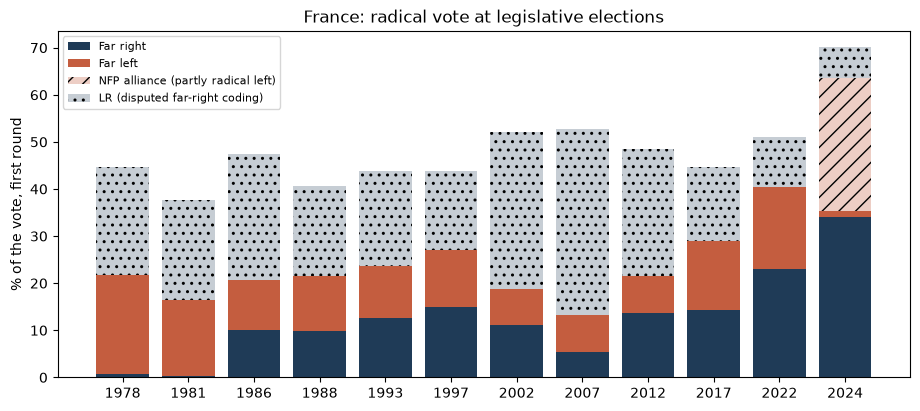

,far_right,far_left,partial,radical_min,radical_central,radical_max,disputed,radical_with_LR
"France, election",,,,,,,,
1978,0.8,21.1,0.0,21.8,21.8,21.8,22.8,44.7
1981,0.3,16.2,0.0,16.5,16.5,16.5,21.2,37.8
1986,10.1,10.6,0.0,20.6,20.6,20.6,26.8,47.5
1988,9.9,11.5,0.0,21.5,21.5,21.5,19.1,40.5
1993,12.7,10.9,0.0,23.6,23.6,23.6,20.2,43.8
1997,14.9,12.1,0.0,27.0,27.0,27.0,16.8,43.8
2002,11.1,7.6,0.0,18.8,18.8,18.8,33.4,52.1
2007,5.5,7.7,0.0,13.2,13.2,13.2,39.5,52.7
2012,13.6,7.9,0.0,21.5,21.5,21.5,27.1,48.6


In [3]:
print(f"LFI + PCF were {NFP_RADICAL_SHARE:.0%} of the NUPES vote in 2022")

france = elections[(elections.iso3c == 'FRA') & (elections.edate.dt.year >= 1978)].set_index('edate')
france['radical_min'] = france.radical
france['radical_max'] = france.radical + france.partial
france['radical_with_LR'] = france.radical_central + france.disputed

fig, ax = plt.subplots(figsize=(11, 4.5))
x = france.index.strftime('%Y')
ax.bar(x, france.far_right, color='#1f3b57', label='Far right')
ax.bar(x, france.far_left, bottom=france.far_right, color='#c45d3f', label='Far left')
ax.bar(x, france.partial, bottom=france.radical, color='#c45d3f', alpha=.3, hatch='//', label='NFP alliance (partly radical left)')
ax.bar(x, france.disputed, bottom=france.radical + france.partial, color='#1f3b57', alpha=.25, hatch='..', label='LR (disputed far-right coding)')
ax.set_ylabel('% of the vote, first round')
ax.set_title('France: radical vote at legislative elections')
ax.legend(fontsize=8, loc='upper left')
plt.show()
france[['far_right', 'far_left', 'partial', 'radical_min', 'radical_central', 'radical_max', 'disputed', 'radical_with_LR']].set_index(x).rename_axis('France, election')

## 3. Around each reference episode

Radical vote at the last election before each episode and at the last election during it (or up to 12 months after it ends), as in `02_shock_numbers.ipynb`. France 2024 uses the central NFP estimate.

In the table of parties that moved most, lists of the same family are added up first: Spain's IU, Podemos and their successive alliances count as **Podemos–IU and allies**, and France's LFI, PCF and Left Front (plus the NFP's estimated radical part) as **LFI + PCF**. Otherwise a list changing its name would look like one party collapsing and another surging.

In [4]:
def around(ep):
    e = elections[elections.iso3c == ep.iso3].set_index('edate')
    before = e[e.index < ep.start_date].tail(1)
    during = e[(e.index >= ep.start_date) & (e.index <= ep.end_date + pd.DateOffset(months=12))].tail(1)
    return before, during

rows = []
for ep in episodes.itertuples():
    before, during = around(ep)
    if before.empty or during.empty:
        continue
    b, d = before.iloc[0], during.iloc[0]
    rows.append({'shock': ep.shock, 'episode': ep.episode_id,
                 'elections': f'{before.index[0]:%Y} → {during.index[0]:%b %Y}',
                 'far_right_before': b.far_right, 'far_right_after': d.far_right,
                 'far_left_before': b.far_left_central, 'far_left_after': d.far_left_central,
                 'radical_before': b.radical_central, 'radical_after': d.radical_central,
                 'radical_change': d.radical_central - b.radical_central})
around_episodes = pd.DataFrame(rows).set_index('episode')
named(around_episodes)

,shock,elections,far_right_before,far_right_after,far_left_before,far_left_after,radical_before,radical_after,radical_change
episode,,,,,,,,,
Belgium 2010–11,S1,2007 → Jun 2010,14.0,9.6,0.8,1.5,14.8,11.1,-3.7
Spain 2015–16,S1,2011 → Jun 2016,0.0,0.2,9.2,21.9,9.2,22.1,12.9
France 2024–25,S1,2022 → Jun 2024,22.9,34.1,17.4,19.0,40.4,53.2,12.8
Spain 2008–13,S2,2008 → Nov 2011,0.0,0.0,4.6,9.2,4.6,9.2,4.6
Greece 2008–13,S2,2007 → Jun 2012,3.8,16.0,13.2,31.4,17.0,47.4,30.4
Portugal 2008–13,S2,2005 → Jun 2011,0.0,0.0,13.2,12.6,13.2,12.6,-0.6
Ireland 2008–13,S2,2007 → Feb 2011,0.0,0.0,0.6,1.1,0.6,1.1,0.4
Austria 2019,S3,2017 → Sep 2019,26.0,16.2,0.8,0.7,26.7,16.9,-9.9
Spain 2018,S3,2016 → Apr 2019,0.2,10.3,21.9,15.5,22.1,25.8,3.7


In [5]:
# Which radical parties moved most (vote share, points). Lists of the same family are added up first
# (see data/reference/party_lists.csv), and the NFP counts only at its estimated radical part.

def radical_movers(ep, n=3):
    before, during = around(ep)
    d = votes[(votes.iso3c == ep.iso3) & votes.group.isin(['far_right', 'far_left', 'partial'])].copy()
    d['pct'] = d.pct.where(d.group != 'partial', d.pct * NFP_RADICAL_SHARE)
    d['party'] = d.party_id.map(FAMILY).fillna(d.party)
    share = lambda date: d[d.edate == date].groupby('party').pct.sum()
    diff = share(during.index[0]).sub(share(before.index[0]), fill_value=0)
    fmt = lambda s: ', '.join(f'{k} {v:+.1f}' for k, v in s.items()) or '—'
    return {'episode': ep.episode_id,
            'gains': fmt(diff[diff >= 0.5].sort_values(ascending=False).head(n)),
            'losses': fmt(diff[diff <= -0.5].sort_values().head(n))}

movers = pd.DataFrame([radical_movers(ep) for ep in episodes.itertuples() if ep.episode_id in around_episodes.index]).set_index('episode')
named(movers)

,gains,losses
episode,,
Belgium 2010–11,"PP +1.3, PvdA/PTB +0.7","VB -4.2, FN/NF -1.5"
Spain 2015–16,"Podemos–IU and allies +14.1, EH Bildu +0.8","AMAIUR -1.4, BNG -0.8"
France 2024–25,"RN +10.6, UXD +4.0, LFI + PCF +1.6",R -3.5
Spain 2008–13,"Podemos–IU and allies +3.3, AMAIUR +1.4",—
Greece 2008–13,"SYRIZA +21.8, ANEL +7.5, XA +6.9","KKE -3.7, LAOS -2.2"
Portugal 2008–13,PCP +0.5,BE -1.1
Ireland 2008–13,—,—
Austria 2019,—,FPÖ -9.8
Spain 2018,VOX +10.1,Podemos–IU and allies -7.1


## 4. The eight countries over time

Far right and far left at each election since 1990; shaded bands are the reference episodes in that country. Greece's far-left line drops after 2015 because PopuList stops classing SYRIZA as far left then.

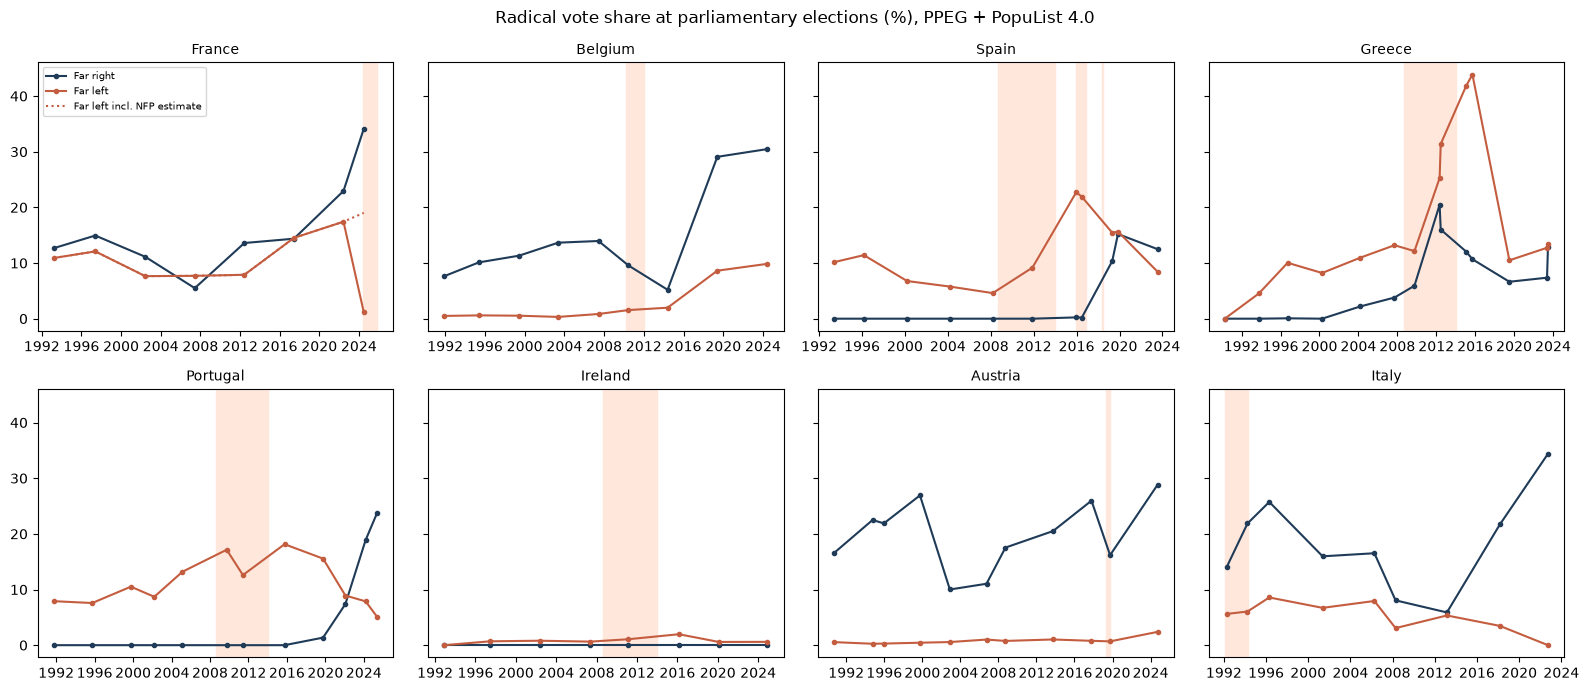

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, (iso3, name) in zip(axes.flat, COUNTRIES.items()):
    e = elections[(elections.iso3c == iso3) & (elections.edate.dt.year >= 1990)]
    ax.plot(e.edate, e.far_right, marker='o', ms=3, color='#1f3b57', label='Far right')
    ax.plot(e.edate, e.far_left, marker='o', ms=3, color='#c45d3f', label='Far left')
    if iso3 == 'FRA':
        ax.plot(e.edate, e.far_left + e.partial * NFP_RADICAL_SHARE, ls=':', color='#c45d3f', label='Far left incl. NFP estimate')
    for ep in episodes[episodes.iso3 == iso3].itertuples():
        ax.axvspan(max(ep.start_date, pd.Timestamp('1990-01-01')), ep.end_date, color='#ffe7dc')
    ax.set_title(name, fontsize=10)
axes.flat[0].legend(fontsize=7)
fig.suptitle('Radical vote share at parliamentary elections (%), PPEG + PopuList 4.0')
plt.tight_layout()
plt.show()

## 5. Latest election in each country

France is shown with its central NFP estimate; its minimum and maximum are in section 2.

In [7]:
latest = elections.sort_values('edate').groupby('iso3c').tail(1).set_index('country')
latest['election'] = latest.edate.dt.strftime('%b %Y')
latest = latest.sort_values('radical_central', ascending=False)
latest[['election', 'far_right', 'far_left_central', 'radical_central', 'disputed']].rename_axis('country (latest election)')

,election,far_right,far_left_central,radical_central,disputed
country (latest election),,,,,
France,Jun 2024,34.1,19.0,53.2,6.6
Belgium,Jun 2024,30.5,9.9,40.3,0.0
Italy,Sep 2022,34.4,0.0,34.4,0.0
Austria,Sep 2024,28.8,2.4,31.2,0.0
Portugal,May 2025,23.7,5.1,28.8,0.0
Greece,Jun 2023,12.8,13.4,26.2,0.0
Spain,Jul 2023,12.5,8.4,20.9,0.0
Ireland,Nov 2024,0.0,0.6,0.6,0.0


## 6. Where France's parties stand (CHES 2024)

Expert placements: left–right (0 left, 10 right), GAL–TAN (0 libertarian, 10 traditional–authoritarian) and position on European integration (1 strongly against, 7 strongly for). Useful for the LR question: is LR placed closer to RN or to the centre?

,lrgen,galtan,eu_position
France: party,,,
FI,0.8,1.8,3.0
PCF,1.7,3.5,3.1
LE/EELV,2.3,1.7,6.2
PS,3.5,2.7,6.3
MoDem,5.4,4.5,6.8
RE,6.3,4.1,6.3
Horizons,6.6,5.3,6.4
LR,7.7,7.2,5.3
RN,8.8,8.4,2.2


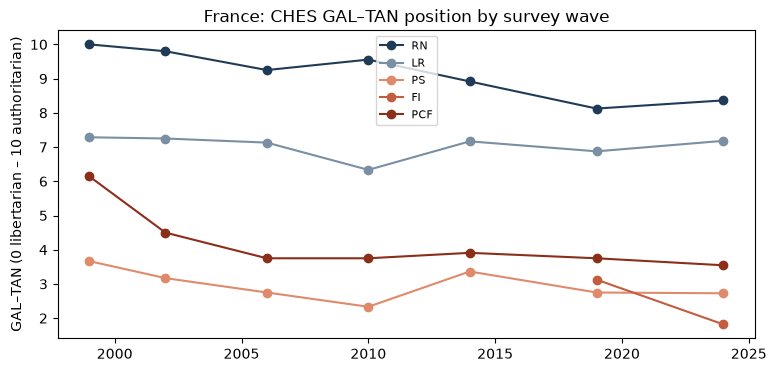

In [8]:
ches = pd.read_csv(RAW / 'ches/1999-2024_CHES_dataset_meansV2.csv')
fr_ches = ches[(ches.country == 6)].copy()
fr_ches['party'] = fr_ches.party.replace({'FN': 'RN', 'UMP': 'LR', 'RPR': 'LR', 'MODEM': 'MoDem', 'LREM': 'RE'})
latest_wave = fr_ches.year.max()
positions = (fr_ches[fr_ches.year == latest_wave].set_index('party')[['lrgen', 'galtan', 'eu_position']]
             .sort_values('lrgen'))
display(positions.rename_axis('France: party'))

fig, ax = plt.subplots(figsize=(9, 4))
for party, color in [('RN', '#1f3b57'), ('LR', '#7a8fa3'), ('PS', '#e08a6c'), ('FI', '#c45d3f'), ('PCF', '#8b2e1a')]:
    s = fr_ches[fr_ches.party == party].sort_values('year')
    ax.plot(s.year, s.galtan, marker='o', label=party, color=color)
ax.set_ylabel('GAL–TAN (0 libertarian – 10 authoritarian)')
ax.set_title('France: CHES GAL–TAN position by survey wave')
ax.legend(fontsize=8)
plt.show()

## 7. Summary of findings

Written from the tables above, so it updates with the data.

In [9]:
fr24, fr22 = france.iloc[-1], france.iloc[-2]
first_fr = france.iloc[0]
out = ['### France',
       f"- **2024 radical vote: {fr24.radical_min:.0f}–{fr24.radical_max:.0f}% (central {fr24.radical_central:.0f}%)**, "
       f"up from {fr22.radical_central:.0f}% in 2022. The range is the NFP alliance; adding LR (disputed) gives {fr24.radical_with_LR:.0f}%.",
       f"- **Far right at {'a record ' if fr24.far_right >= france.far_right.max() else ''}{fr24.far_right:.0f}%** "
       f"(RN and its allies, Reconquête), against {fr22.far_right:.0f}% in 2022 and {first_fr.far_right:.0f}% in {france.index[0]:%Y}.",
       f"- **The radical vote changed side:** in {france.index[0]:%Y} it was almost all far left ({first_fr.far_left:.0f}%, mainly the PCF, "
       f"far right {first_fr.far_right:.0f}%); in 2024 the far right leads with {fr24.far_right:.0f}% against "
       f"{fr24.far_left + NFP_RADICAL_SHARE * fr24.partial:.0f}% for the far left (NFP estimate).",
       ]
lr, rn, re_ = positions.loc['LR'], positions.loc['RN'], positions.loc['RE'] if 'RE' in positions.index else None
if re_ is not None:
    closer = 'RN' if abs(lr.galtan - rn.galtan) < abs(lr.galtan - re_.galtan) else 'Renaissance'
    out.append(f"- **LR coding:** CHES {latest_wave} places LR at {lr.galtan:.1f} on GAL–TAN, against {rn.galtan:.1f} for RN and "
               f"{re_.galtan:.1f} for Renaissance, so closer to {closer} on that axis; on left–right LR is {lr.lrgen:.1f} vs RN {rn.lrgen:.1f}.")

out += ['', '### Around the shocks']
for shock, title in {'S1': 'Government collapse', 'S2': 'Financial crisis', 'S3': 'Integrity scandal'}.items():
    a = around_episodes[around_episodes.shock == shock]
    lead = lambda ep: (movers.loc[ep, 'gains'] if movers.loc[ep, 'gains'] != '—' else movers.loc[ep, 'losses']).split(', ')[0]
    parts = [f"{LABEL[ep]} {r.radical_change:+.0f} pts ({lead(ep)})" for ep, r in a.iterrows()]
    out.append(f"- **{shock} · {title}:** " + '; '.join(parts) + '.')
s2 = around_episodes[around_episodes.shock == 'S2']
out.append(f"- The financial crisis is the clearest case: across {', '.join(LABEL[e] for e in s2.index)} the radical vote changed by {s2.radical_change.min():+.0f} to "
           f"{s2.radical_change.max():+.0f} points, the largest rise in Greece (SYRIZA, Golden Dawn, ANEL).")
if 'S3_AT_2019' in around_episodes.index:
    out.append(f"- A scandal can hit the radical party itself: in Austria 2019 the FPÖ was at the centre of the Ibiza affair and "
               f"the radical vote changed by {around_episodes.loc['S3_AT_2019', 'radical_change']:+.0f} points.")

rank = list(latest.index).index('France') + 1
out += ['', '### France among the eight countries',
        f"- At its latest election France has the **{['highest', 'second highest', 'third highest'][rank - 1] if rank <= 3 else f'{rank}th highest'} "
        f"radical vote** of the eight countries ({latest.loc['France', 'radical_central']:.0f}% central estimate), "
        f"ahead of " + ', '.join(f"{c} {v:.0f}%" for c, v in latest.radical_central.drop('France').head(3).items()) + '.',
        '', '### Read with care',
        '- PopuList lists only parties it has classified; an unlisted party is not thereby moderate. '
        '(Ireland reads near zero because PopuList classes Sinn Féin as populist, not far left; '
        'Belgium counts N-VA as far right only from 2019, as PopuList does.)',
        '- PPEG alliance rows hide member parties (France 2024 NFP); the central estimate assumes 2022 proportions.',
        "- Class changes are dated: Greece's far left drops after 2015 because PopuList stops classing SYRIZA as far left then, not because its vote collapsed.",
        '- Vote shares are first-round, list-level results; changes are not corrected for Europe-wide trends.']
Markdown('\n'.join(out))

### France
- **2024 radical vote: 35–63% (central 53%)**, up from 40% in 2022. The range is the NFP alliance; adding LR (disputed) gives 60%.
- **Far right at a record 34%** (RN and its allies, Reconquête), against 23% in 2022 and 1% in 1978.
- **The radical vote changed side:** in 1978 it was almost all far left (21%, mainly the PCF, far right 1%); in 2024 the far right leads with 34% against 19% for the far left (NFP estimate).
- **LR coding:** CHES 2024 places LR at 7.2 on GAL–TAN, against 8.4 for RN and 4.1 for Renaissance, so closer to RN on that axis; on left–right LR is 7.7 vs RN 8.8.

### Around the shocks
- **S1 · Government collapse:** Belgium 2010–11 -4 pts (PP +1.3); Spain 2015–16 +13 pts (Podemos–IU and allies +14.1); France 2024–25 +13 pts (RN +10.6).
- **S2 · Financial crisis:** Spain 2008–13 +5 pts (Podemos–IU and allies +3.3); Greece 2008–13 +30 pts (SYRIZA +21.8); Portugal 2008–13 -1 pts (PCP +0.5); Ireland 2008–13 +0 pts (—).
- **S3 · Integrity scandal:** Austria 2019 -10 pts (FPÖ -9.8); Spain 2018 +4 pts (VOX +10.1); Italy 1992–94 +22 pts (LN +8.4).
- The financial crisis is the clearest case: across Spain 2008–13, Greece 2008–13, Portugal 2008–13, Ireland 2008–13 the radical vote changed by -1 to +30 points, the largest rise in Greece (SYRIZA, Golden Dawn, ANEL).
- A scandal can hit the radical party itself: in Austria 2019 the FPÖ was at the centre of the Ibiza affair and the radical vote changed by -10 points.

### France among the eight countries
- At its latest election France has the **highest radical vote** of the eight countries (53% central estimate), ahead of Belgium 40%, Italy 34%, Austria 31%.

### Read with care
- PopuList lists only parties it has classified; an unlisted party is not thereby moderate. (Ireland reads near zero because PopuList classes Sinn Féin as populist, not far left; Belgium counts N-VA as far right only from 2019, as PopuList does.)
- PPEG alliance rows hide member parties (France 2024 NFP); the central estimate assumes 2022 proportions.
- Class changes are dated: Greece's far left drops after 2015 because PopuList stops classing SYRIZA as far left then, not because its vote collapsed.
- Vote shares are first-round, list-level results; changes are not corrected for Europe-wide trends.